In [1]:
from google.colab import files
uploaded = files.upload()

Saving predictive_maintenance.csv to predictive_maintenance.csv


In [2]:
import pandas as pd
import io

filename = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

df_class = pd.read_csv(
    io.BytesIO(uploaded[filename])
)

print("Dimensions :", df_class.shape)
print("\nColonnes :")
print(df_class.columns.tolist())

display(df_class.head())

Dimensions : (10000, 10)

Colonnes :
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [3]:
print("Dimensions :", df_class.shape)

print("\nValeurs manquantes :")
print(df_class.isnull().sum())

print("\nDoublons :", df_class.duplicated().sum())

print("\nTypes des colonnes :")
print(df_class.dtypes)

print("\nRépartition des classes :")
print(df_class["Failure Type"].value_counts())

Dimensions : (10000, 10)

Valeurs manquantes :
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64

Doublons : 0

Types des colonnes :
UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Target                       int64
Failure Type                object
dtype: object

Répartition des classes :
Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count,

In [4]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# Séparer les variables explicatives et la cible
X = df_class.drop(
    columns=["UDI", "Product ID", "Target", "Failure Type"]
)

y = df_class["Failure Type"]

# Encoder la variable catégorielle Type
X = pd.get_dummies(
    X,
    columns=["Type"],
    dtype=int
)

# Encoder les classes de panne
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("Dimensions de X :", X.shape)
print("Nombre de classes :", len(label_encoder.classes_))

print("\nCorrespondance des classes :")
for i, name in enumerate(label_encoder.classes_):
    print(f"{i} : {name}")

Dimensions de X : (10000, 8)
Nombre de classes : 6

Correspondance des classes :
0 : Heat Dissipation Failure
1 : No Failure
2 : Overstrain Failure
3 : Power Failure
4 : Random Failures
5 : Tool Wear Failure


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train :", X_train.shape)
print("Test :", X_test.shape)

Train : (8000, 8)
Test : (2000, 8)


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Standardisation terminée !")
print("Train :", X_train_scaled.shape)
print("Test :", X_test_scaled.shape)

Standardisation terminée !
Train : (8000, 8)
Test : (2000, 8)


In [7]:
!pip -q install imbalanced-learn

In [8]:
from imblearn.over_sampling import SMOTENC
from collections import Counter
import numpy as np

print("Avant SMOTENC :")
print(Counter(y_train))

# Colonnes correspondant à Type_L, Type_M, Type_H
categorical_indices = [
    i for i, col in enumerate(X_train.columns)
    if col.startswith("Type_")
]

# Nombre d'observations souhaité pour chaque panne
sampling_strategy = {
    classe: 500
    for classe, nombre in Counter(y_train).items()
    if classe != 1 and nombre < 500
}

smote = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=sampling_strategy,
    random_state=42,
    k_neighbors=5
)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("\nAprès SMOTENC :")
print(Counter(y_train_balanced))

print("\nDimensions :")
print("X_train_balanced :", X_train_balanced.shape)
print("y_train_balanced :", y_train_balanced.shape)

Avant SMOTENC :
Counter({np.int64(1): 7722, np.int64(0): 90, np.int64(3): 76, np.int64(2): 62, np.int64(5): 36, np.int64(4): 14})

Après SMOTENC :
Counter({np.int64(1): 7722, np.int64(5): 500, np.int64(4): 500, np.int64(3): 500, np.int64(0): 500, np.int64(2): 500})

Dimensions :
X_train_balanced : (10222, 8)
y_train_balanced : (10222,)


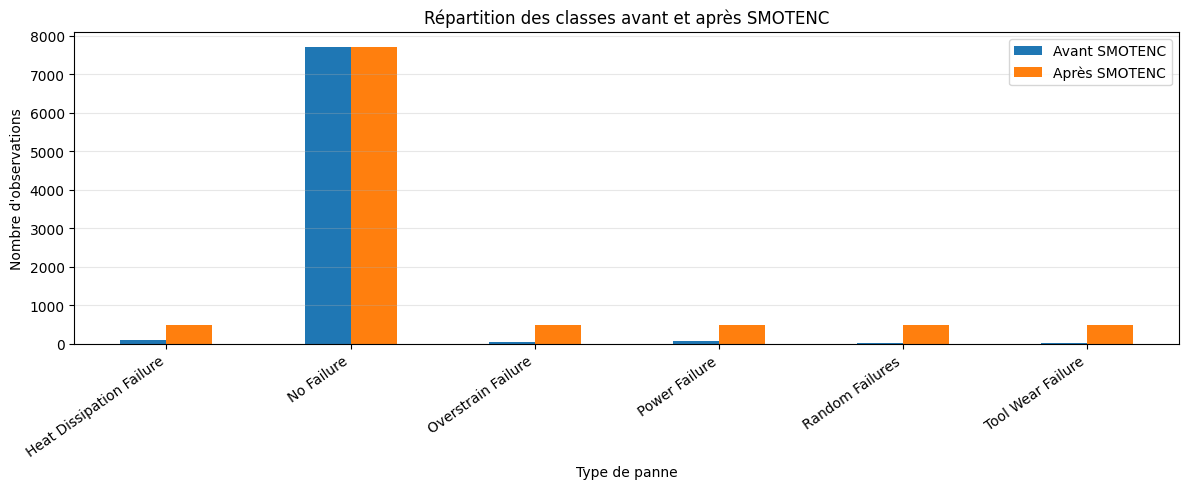

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

counts_before = pd.Series(y_train).value_counts().sort_index()
counts_after = pd.Series(y_train_balanced).value_counts().sort_index()

comparison = pd.DataFrame({
    "Avant SMOTENC": counts_before,
    "Après SMOTENC": counts_after
})

comparison.index = label_encoder.inverse_transform(
    comparison.index.to_numpy()
)

comparison.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Répartition des classes avant et après SMOTENC")
plt.xlabel("Type de panne")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
import torch
import numpy as np
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

# Conversion en tenseurs
X_train_tensor = torch.tensor(
    np.asarray(X_train_balanced),
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    np.asarray(y_train_balanced),
    dtype=torch.long
)

X_test_tensor = torch.tensor(
    np.asarray(X_test_scaled),
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    np.asarray(y_test),
    dtype=torch.long
)

# DataLoader
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

print("X_train :", X_train_tensor.shape)
print("y_train :", y_train_tensor.shape)
print("X_test :", X_test_tensor.shape)
print("y_test :", y_test_tensor.shape)

X_train : torch.Size([10222, 8])
y_train : torch.Size([10222])
X_test : torch.Size([2000, 8])
y_test : torch.Size([2000])


In [11]:
import torch
import numpy as np
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

# Conversion en tenseurs
X_train_tensor = torch.tensor(
    np.asarray(X_train_balanced),
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    np.asarray(y_train_balanced),
    dtype=torch.long
)

X_test_tensor = torch.tensor(
    np.asarray(X_test_scaled),
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    np.asarray(y_test),
    dtype=torch.long
)

# DataLoader
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

print("X_train :", X_train_tensor.shape)
print("y_train :", y_train_tensor.shape)
print("X_test :", X_test_tensor.shape)
print("y_test :", y_test_tensor.shape)

X_train : torch.Size([10222, 8])
y_train : torch.Size([10222])
X_test : torch.Size([2000, 8])
y_test : torch.Size([2000])


In [12]:
import torch.nn as nn

class DNNClassifier(nn.Module):

    def __init__(self, input_size=8, num_classes=6):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)


model = DNNClassifier()

print(model)

DNNClassifier(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=6, bias=True)
  )
)


In [13]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 50

print("Modèle prêt pour l'entraînement !")

Modèle prêt pour l'entraînement !


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTENC
from collections import Counter

# Découpage des données d'entraînement originales
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

# Standardisation sans fuite de données
scaler_dnn = StandardScaler()

X_subtrain_scaled = scaler_dnn.fit_transform(X_subtrain)
X_val_scaled = scaler_dnn.transform(X_val)

# Repérer les variables catégorielles Type
categorical_indices = [
    i for i, col in enumerate(X_subtrain.columns)
    if col.startswith("Type_")
]

# Augmenter les classes minoritaires
strategy = {
    classe: 500
    for classe, nombre in Counter(y_subtrain).items()
    if classe != 1 and nombre < 500
}

smote_dnn = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=strategy,
    random_state=42,
    k_neighbors=5
)

X_subtrain_balanced, y_subtrain_balanced = smote_dnn.fit_resample(
    X_subtrain_scaled,
    y_subtrain
)

print("Train réel :", X_subtrain.shape)
print("Validation :", X_val.shape)
print("Train après SMOTENC :", X_subtrain_balanced.shape)
print("Classes :", Counter(y_subtrain_balanced))

Train réel : (6400, 8)
Validation : (1600, 8)
Train après SMOTENC : (8678, 8)
Classes : Counter({np.int64(1): 6178, np.int64(0): 500, np.int64(3): 500, np.int64(2): 500, np.int64(5): 500, np.int64(4): 500})


In [15]:
import torch
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

torch.manual_seed(42)

X_train_tensor = torch.tensor(
    np.asarray(X_subtrain_balanced),
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    np.asarray(y_subtrain_balanced),
    dtype=torch.long
)

X_val_tensor = torch.tensor(
    np.asarray(X_val_scaled),
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    np.asarray(y_val),
    dtype=torch.long
)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=32,
    shuffle=True
)

print("Train :", X_train_tensor.shape)
print("Validation :", X_val_tensor.shape)

Train : torch.Size([8678, 8])
Validation : torch.Size([1600, 8])


In [16]:
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(42)

model = DNNClassifier(input_size=8, num_classes=6)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 50

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(epochs):

    # Entraînement
    model.train()

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

    # Évaluation sur les deux ensembles
    model.eval()

    with torch.no_grad():

        train_outputs = model(X_train_tensor)
        val_outputs = model(X_val_tensor)

        train_loss = criterion(
            train_outputs, y_train_tensor
        ).item()

        val_loss = criterion(
            val_outputs, y_val_tensor
        ).item()

        train_predictions = torch.argmax(train_outputs, dim=1)
        val_predictions = torch.argmax(val_outputs, dim=1)

        train_acc = (
            train_predictions == y_train_tensor
        ).float().mean().item()

        val_acc = (
            val_predictions == y_val_tensor
        ).float().mean().item()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

Epoch 10/50 | Train Loss: 0.1702 | Val Loss: 0.1531 | Train Acc: 0.9321 | Val Acc: 0.9525
Epoch 20/50 | Train Loss: 0.1222 | Val Loss: 0.1274 | Train Acc: 0.9539 | Val Acc: 0.9600
Epoch 30/50 | Train Loss: 0.0995 | Val Loss: 0.1400 | Train Acc: 0.9659 | Val Acc: 0.9594
Epoch 40/50 | Train Loss: 0.0776 | Val Loss: 0.1402 | Train Acc: 0.9748 | Val Acc: 0.9619
Epoch 50/50 | Train Loss: 0.0711 | Val Loss: 0.1368 | Train Acc: 0.9764 | Val Acc: 0.9669


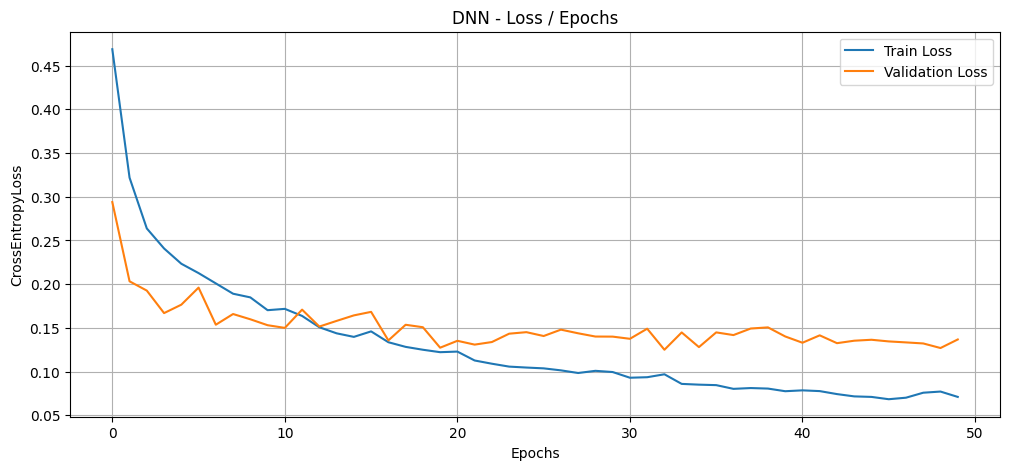

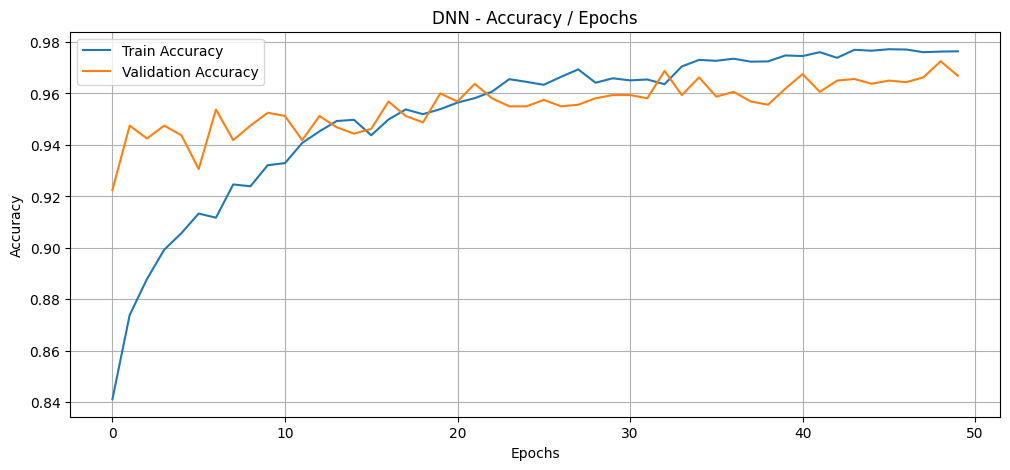

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.title("DNN - Loss / Epochs")
plt.xlabel("Epochs")
plt.ylabel("CrossEntropyLoss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 5))

plt.plot(history["train_acc"], label="Train Accuracy")
plt.plot(history["val_acc"], label="Validation Accuracy")

plt.title("DNN - Accuracy / Epochs")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

model.eval()

with torch.no_grad():
    outputs = model(X_val_tensor)
    y_val_pred = torch.argmax(outputs, dim=1).numpy()

print("=== RAPPORT DE CLASSIFICATION : VALIDATION ===")

print(
    classification_report(
        y_val,
        y_val_pred,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

print("Accuracy :", accuracy_score(y_val, y_val_pred))
print("Precision macro :", precision_score(
    y_val, y_val_pred, average="macro", zero_division=0
))
print("Recall macro :", recall_score(
    y_val, y_val_pred, average="macro", zero_division=0
))
print("F1-score macro :", f1_score(
    y_val, y_val_pred, average="macro", zero_division=0
))

=== RAPPORT DE CLASSIFICATION : VALIDATION ===
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.83      0.83      0.83        18
              No Failure       0.99      0.98      0.98      1544
      Overstrain Failure       0.71      0.92      0.80        13
           Power Failure       0.67      0.67      0.67        15
         Random Failures       0.00      0.00      0.00         3
       Tool Wear Failure       0.11      0.29      0.16         7

                accuracy                           0.97      1600
               macro avg       0.55      0.61      0.57      1600
            weighted avg       0.98      0.97      0.97      1600

Accuracy : 0.966875
Precision macro : 0.5512991734874706
Recall macro : 0.6142458577691737
F1-score macro : 0.5739486844966296


In [19]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

model.eval()

with torch.no_grad():
    outputs = model(X_val_tensor)
    y_val_pred = torch.argmax(outputs, dim=1).numpy()

print("=== RAPPORT DE CLASSIFICATION : VALIDATION ===")

print(
    classification_report(
        y_val,
        y_val_pred,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

print("Accuracy :", accuracy_score(y_val, y_val_pred))
print("Precision macro :", precision_score(
    y_val, y_val_pred, average="macro", zero_division=0
))
print("Recall macro :", recall_score(
    y_val, y_val_pred, average="macro", zero_division=0
))
print("F1-score macro :", f1_score(
    y_val, y_val_pred, average="macro", zero_division=0
))

=== RAPPORT DE CLASSIFICATION : VALIDATION ===
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.83      0.83      0.83        18
              No Failure       0.99      0.98      0.98      1544
      Overstrain Failure       0.71      0.92      0.80        13
           Power Failure       0.67      0.67      0.67        15
         Random Failures       0.00      0.00      0.00         3
       Tool Wear Failure       0.11      0.29      0.16         7

                accuracy                           0.97      1600
               macro avg       0.55      0.61      0.57      1600
            weighted avg       0.98      0.97      0.97      1600

Accuracy : 0.966875
Precision macro : 0.5512991734874706
Recall macro : 0.6142458577691737
F1-score macro : 0.5739486844966296


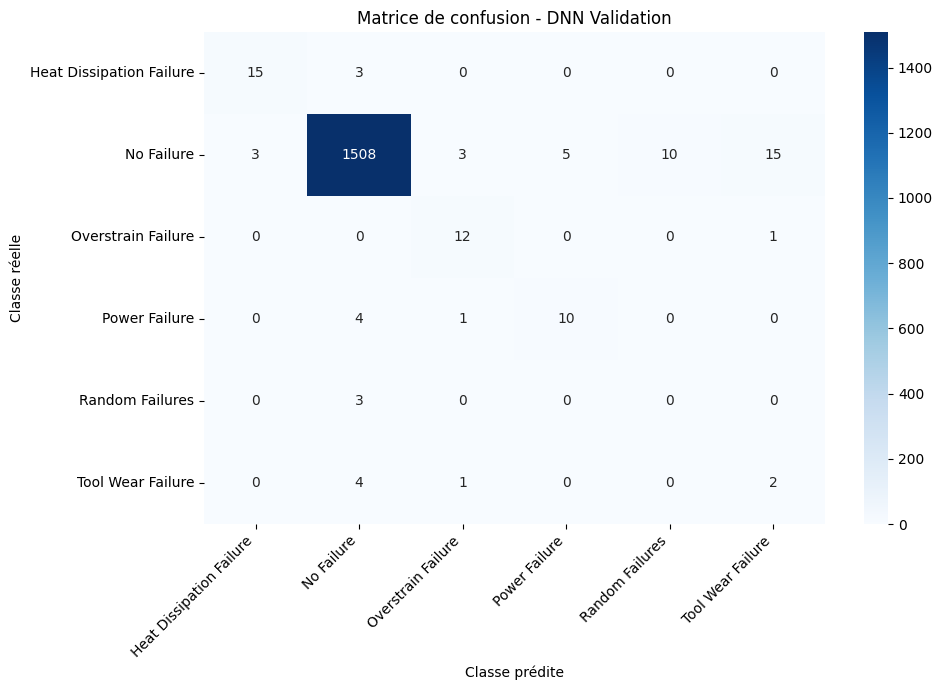

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=range(len(label_encoder.classes_))
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Matrice de confusion - DNN Validation")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
import torch
import torch.nn as nn

class FlexibleDNN(nn.Module):

    def __init__(
        self,
        input_size=8,
        hidden_layers=(64, 32),
        num_classes=6
    ):
        super().__init__()

        layers = []
        previous_size = input_size

        for neurons in hidden_layers:
            layers.append(nn.Linear(previous_size, neurons))
            layers.append(nn.ReLU())
            previous_size = neurons

        layers.append(nn.Linear(previous_size, num_classes))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [22]:
model1 = FlexibleDNN(hidden_layers=(64, 32))
model2 = FlexibleDNN(hidden_layers=(128, 64))
model3 = FlexibleDNN(hidden_layers=(64, 32, 16))

print("Architecture 1 :")
print(model1)

print("\nArchitecture 2 :")
print(model2)

print("\nArchitecture 3 :")
print(model3)

Architecture 1 :
FlexibleDNN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=6, bias=True)
  )
)

Architecture 2 :
FlexibleDNN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=6, bias=True)
  )
)

Architecture 3 :
FlexibleDNN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=6, bias=True)
  )
)


In [23]:
import numpy as np
import torch
import torch.nn as nn

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTENC
from torch.utils.data import TensorDataset, DataLoader
from collections import Counter

class TorchDNNClassifier(ClassifierMixin, BaseEstimator):

    def __init__(
        self,
        hidden_layers=(64, 32),
        learning_rate=0.001,
        optimizer_name="Adam",
        epochs=30,
        batch_size=32,
        random_state=42
    ):
        self.hidden_layers = hidden_layers
        self.learning_rate = learning_rate
        self.optimizer_name = optimizer_name
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):

        torch.manual_seed(self.random_state)
        np.random.seed(self.random_state)

        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.int64)

        self.classes_ = np.unique(y)

        # Standardisation sur le train du fold uniquement
        self.scaler_ = StandardScaler()
        X_scaled = self.scaler_.fit_transform(X)

        # Les 3 dernières colonnes correspondent à Type_H/L/M
        categorical_indices = [5, 6, 7]

        # Rééquilibrage partiel des classes minoritaires
        counts = Counter(y)

        strategy = {
            cls: 500
            for cls, count in counts.items()
            if cls != 1 and count < 500
        }

        if strategy:
            min_count = min(counts[cls] for cls in strategy)

            smote = SMOTENC(
                categorical_features=categorical_indices,
                sampling_strategy=strategy,
                random_state=self.random_state,
                k_neighbors=min(5, min_count - 1)
            )

            X_scaled, y = smote.fit_resample(
                X_scaled, y
            )

        X_tensor = torch.tensor(
            np.asarray(X_scaled),
            dtype=torch.float32
        )

        y_tensor = torch.tensor(
            np.asarray(y),
            dtype=torch.long
        )

        loader = DataLoader(
            TensorDataset(X_tensor, y_tensor),
            batch_size=self.batch_size,
            shuffle=True,
            generator=torch.Generator().manual_seed(self.random_state)
        )

        self.model_ = FlexibleDNN(
            input_size=X_tensor.shape[1],
            hidden_layers=self.hidden_layers,
            num_classes=6
        )

        criterion = nn.CrossEntropyLoss()

        if self.optimizer_name == "Adam":
            optimizer = torch.optim.Adam(
                self.model_.parameters(),
                lr=self.learning_rate
            )
        elif self.optimizer_name == "SGD":
            optimizer = torch.optim.SGD(
                self.model_.parameters(),
                lr=self.learning_rate
            )
        else:
            raise ValueError("Optimiseur non reconnu")

        for epoch in range(self.epochs):

            self.model_.train()

            for X_batch, y_batch in loader:

                optimizer.zero_grad()

                outputs = self.model_(X_batch)
                loss = criterion(outputs, y_batch)

                loss.backward()
                optimizer.step()

        return self

    def predict(self, X):

        X_scaled = self.scaler_.transform(
            np.asarray(X, dtype=np.float32)
        )

        X_tensor = torch.tensor(
            X_scaled,
            dtype=torch.float32
        )

        self.model_.eval()

        with torch.no_grad():
            outputs = self.model_(X_tensor)
            predictions = torch.argmax(outputs, dim=1)

        return predictions.numpy()

In [24]:
print(X_subtrain.columns.tolist())

['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']


In [25]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score

param_grid = {
    "hidden_layers": [
        (64, 32),
        (128, 64),
        (64, 32, 16)
    ],
    "learning_rate": [0.001, 0.0005],
    "optimizer_name": ["Adam", "SGD"],
    "epochs": [30, 50]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=TorchDNNClassifier(),
    param_grid=param_grid,
    scoring=make_scorer(
        f1_score,
        average="macro",
        zero_division=0
    ),
    cv=cv,
    n_jobs=1,
    verbose=1,
    refit=True,
    error_score="raise"
)

In [27]:
grid_search.fit(
    X_subtrain,
    y_subtrain
)

print("\nMeilleurs hyperparamètres :")
print(grid_search.best_params_)

print("\nMeilleur F1-score macro moyen :")
print(grid_search.best_score_)

Fitting 3 folds for each of 24 candidates, totalling 72 fits

Meilleurs hyperparamètres :
{'epochs': 50, 'hidden_layers': (128, 64), 'learning_rate': 0.001, 'optimizer_name': 'Adam'}

Meilleur F1-score macro moyen :
0.5682704324013291


In [28]:
import pandas as pd

results = pd.DataFrame(grid_search.cv_results_)

columns = [
    "param_hidden_layers",
    "param_learning_rate",
    "param_optimizer_name",
    "param_epochs",
    "mean_test_score",
    "rank_test_score"
]

display(
    results[columns]
    .sort_values("rank_test_score")
    .head(10)
)

,param_hidden_layers,param_learning_rate,param_optimizer_name,param_epochs,mean_test_score,rank_test_score
16,"(128, 64)",0.0010,Adam,50,0.568270,1
18,"(128, 64)",0.0005,Adam,50,0.555974,2
4,"(128, 64)",0.0010,Adam,30,0.551925,3
6,"(128, 64)",0.0005,Adam,30,0.550934,4
20,"(64, 32, 16)",0.0010,Adam,50,0.546684,5
12,"(64, 32)",0.0010,Adam,50,0.545739,6
22,"(64, 32, 16)",0.0005,Adam,50,0.542484,7
0,"(64, 32)",0.0010,Adam,30,0.541898,8
14,"(64, 32)",0.0005,Adam,50,0.534339,9
2,"(64, 32)",0.0005,Adam,30,0.529777,10


In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import pandas as pd

# Meilleur modèle obtenu par GridSearchCV
best_model = grid_search.best_estimator_

# Prédictions sur la validation réelle
# Attention : X_val non standardisé,
# car best_model applique son propre scaler
y_val_pred_optimized = best_model.predict(X_val)

# Comparaison avec le DNN initial
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1-score Macro"
    ],
    "DNN Initial": [
        accuracy_score(y_val, y_val_pred),
        precision_score(y_val, y_val_pred, average="macro", zero_division=0),
        recall_score(y_val, y_val_pred, average="macro", zero_division=0),
        f1_score(y_val, y_val_pred, average="macro", zero_division=0)
    ],
    "DNN Optimized": [
        accuracy_score(y_val, y_val_pred_optimized),
        precision_score(y_val, y_val_pred_optimized, average="macro", zero_division=0),
        recall_score(y_val, y_val_pred_optimized, average="macro", zero_division=0),
        f1_score(y_val, y_val_pred_optimized, average="macro", zero_division=0)
    ]
})

display(comparison.round(4))

print("\n=== CLASSIFICATION REPORT : DNN OPTIMIZED ===")

print(
    classification_report(
        y_val,
        y_val_pred_optimized,
        labels=range(6),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

,Metric,DNN Initial,DNN Optimized
0,Accuracy,0.9669,0.9738
1,Precision Macro,0.5513,0.5674
2,Recall Macro,0.6142,0.6321
3,F1-score Macro,0.5739,0.5962



=== CLASSIFICATION REPORT : DNN OPTIMIZED ===
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.89      0.94      0.92        18
              No Failure       0.99      0.98      0.99      1544
      Overstrain Failure       0.87      1.00      0.93        13
           Power Failure       0.65      0.87      0.74        15
         Random Failures       0.00      0.00      0.00         3
       Tool Wear Failure       0.00      0.00      0.00         7

                accuracy                           0.97      1600
               macro avg       0.57      0.63      0.60      1600
            weighted avg       0.98      0.97      0.98      1600



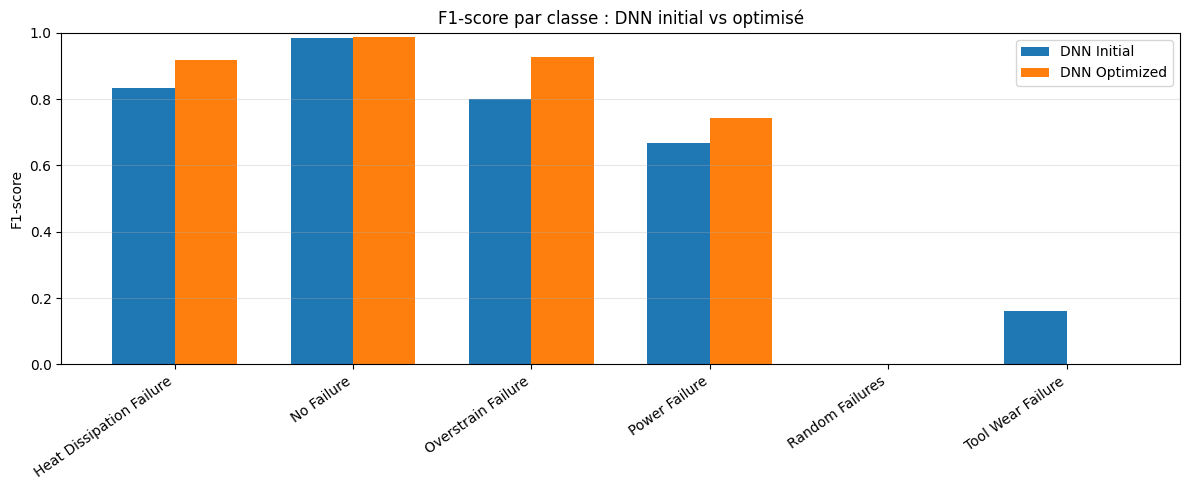

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

classes = label_encoder.classes_

f1_initial = f1_score(
    y_val,
    y_val_pred,
    labels=range(6),
    average=None,
    zero_division=0
)

f1_optimized = f1_score(
    y_val,
    y_val_pred_optimized,
    labels=range(6),
    average=None,
    zero_division=0
)

positions = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    positions - width / 2,
    f1_initial,
    width,
    label="DNN Initial"
)

plt.bar(
    positions + width / 2,
    f1_optimized,
    width,
    label="DNN Optimized"
)

plt.xticks(positions, classes, rotation=35, ha="right")
plt.ylabel("F1-score")
plt.title("F1-score par classe : DNN initial vs optimisé")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
import torch
import torch.nn as nn

class RegularizedDNN(nn.Module):

    def __init__(
        self,
        input_size=8,
        hidden_layers=(128, 64),
        num_classes=6,
        dropout_rate=0.0
    ):
        super().__init__()

        layers = []
        previous_size = input_size

        for neurons in hidden_layers:

            layers.append(nn.Linear(previous_size, neurons))
            layers.append(nn.ReLU())

            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))

            previous_size = neurons

        layers.append(nn.Linear(previous_size, num_classes))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


# Vérification
model_regularized = RegularizedDNN(
    input_size=8,
    hidden_layers=(128, 64),
    num_classes=6,
    dropout_rate=0.2
)

print(model_regularized)

RegularizedDNN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=6, bias=True)
  )
)


In [32]:
import copy
import numpy as np
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def train_regularized_model(
    dropout_rate=0.0,
    weight_decay=0.0,
    early_stopping=False,
    epochs=50,
    patience=10
):
    torch.manual_seed(42)

    model_reg = RegularizedDNN(
        input_size=8,
        hidden_layers=(128, 64),
        num_classes=6,
        dropout_rate=dropout_rate
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model_reg.parameters(),
        lr=0.001,
        weight_decay=weight_decay
    )

    history_reg = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_weights = None
    best_epoch = 0
    counter = 0

    for epoch in range(epochs):

        # Entraînement
        model_reg.train()

        for X_batch, y_batch in train_loader:

            optimizer.zero_grad()

            outputs = model_reg(X_batch)
            loss = criterion(outputs, y_batch)

            loss.backward()
            optimizer.step()

        # Évaluation
        model_reg.eval()

        with torch.no_grad():

            train_outputs = model_reg(X_train_tensor)
            val_outputs = model_reg(X_val_tensor)

            train_loss = criterion(
                train_outputs, y_train_tensor
            ).item()

            val_loss = criterion(
                val_outputs, y_val_tensor
            ).item()

            train_pred = train_outputs.argmax(dim=1)
            val_pred = val_outputs.argmax(dim=1)

            train_acc = (
                train_pred == y_train_tensor
            ).float().mean().item()

            val_acc = (
                val_pred == y_val_tensor
            ).float().mean().item()

        history_reg["train_loss"].append(train_loss)
        history_reg["val_loss"].append(val_loss)
        history_reg["train_acc"].append(train_acc)
        history_reg["val_acc"].append(val_acc)

        # Sauvegarder les meilleurs poids
        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model_reg.state_dict())
            best_epoch = epoch + 1
            counter = 0
        else:
            counter += 1

        if early_stopping and counter >= patience:
            print(f"Early Stopping à l'epoch {epoch + 1}")
            break

    # Restaurer les meilleurs poids uniquement
    # pour le modèle avec Early Stopping
    if early_stopping and best_weights is not None:
        model_reg.load_state_dict(best_weights)

    model_reg.eval()

    with torch.no_grad():
        final_outputs = model_reg(X_val_tensor)
        final_pred = final_outputs.argmax(dim=1).numpy()

    metrics = {
        "Accuracy": accuracy_score(y_val, final_pred),
        "Precision Macro": precision_score(
            y_val, final_pred, average="macro", zero_division=0
        ),
        "Recall Macro": recall_score(
            y_val, final_pred, average="macro", zero_division=0
        ),
        "F1 Macro": f1_score(
            y_val, final_pred, average="macro", zero_division=0
        ),
        "Epochs": len(history_reg["train_loss"])
    }

    return model_reg, history_reg, metrics, final_pred

In [33]:
configurations = {
    "DNN sans régularisation": {
        "dropout_rate": 0.0,
        "weight_decay": 0.0,
        "early_stopping": False
    },

    "DNN + Dropout": {
        "dropout_rate": 0.2,
        "weight_decay": 0.0,
        "early_stopping": False
    },

    "DNN + L2": {
        "dropout_rate": 0.0,
        "weight_decay": 0.0001,
        "early_stopping": False
    },

    "DNN + Dropout + L2 + Early Stopping": {
        "dropout_rate": 0.2,
        "weight_decay": 0.0001,
        "early_stopping": True
    }
}

models_reg = {}
histories_reg = {}
results_reg = {}
predictions_reg = {}

for name, params in configurations.items():

    print(f"\nEntraînement : {name}")

    trained_model, hist, metrics, predictions = (
        train_regularized_model(**params)
    )

    models_reg[name] = trained_model
    histories_reg[name] = hist
    results_reg[name] = metrics
    predictions_reg[name] = predictions

    print(
        f"Epochs : {metrics['Epochs']} | "
        f"Accuracy : {metrics['Accuracy']:.4f} | "
        f"F1 Macro : {metrics['F1 Macro']:.4f}"
    )


Entraînement : DNN sans régularisation
Epochs : 50 | Accuracy : 0.9769 | F1 Macro : 0.6150

Entraînement : DNN + Dropout
Epochs : 50 | Accuracy : 0.9675 | F1 Macro : 0.6161

Entraînement : DNN + L2
Epochs : 50 | Accuracy : 0.9719 | F1 Macro : 0.6112

Entraînement : DNN + Dropout + L2 + Early Stopping
Early Stopping à l'epoch 24
Epochs : 24 | Accuracy : 0.9594 | F1 Macro : 0.5434


In [34]:
import pandas as pd

comparison_reg = pd.DataFrame(results_reg).T

comparison_reg = comparison_reg.sort_values(
    by="F1 Macro",
    ascending=False
)

display(comparison_reg.round(4))

,Accuracy,Precision Macro,Recall Macro,F1 Macro,Epochs
DNN + Dropout,0.9675,0.5741,0.6784,0.6161,50.0
DNN sans régularisation,0.9769,0.5913,0.6436,0.6150,50.0
DNN + L2,0.9719,0.5713,0.6646,0.6112,50.0
DNN + Dropout + L2 + Early Stopping,0.9594,0.5306,0.5601,0.5434,24.0


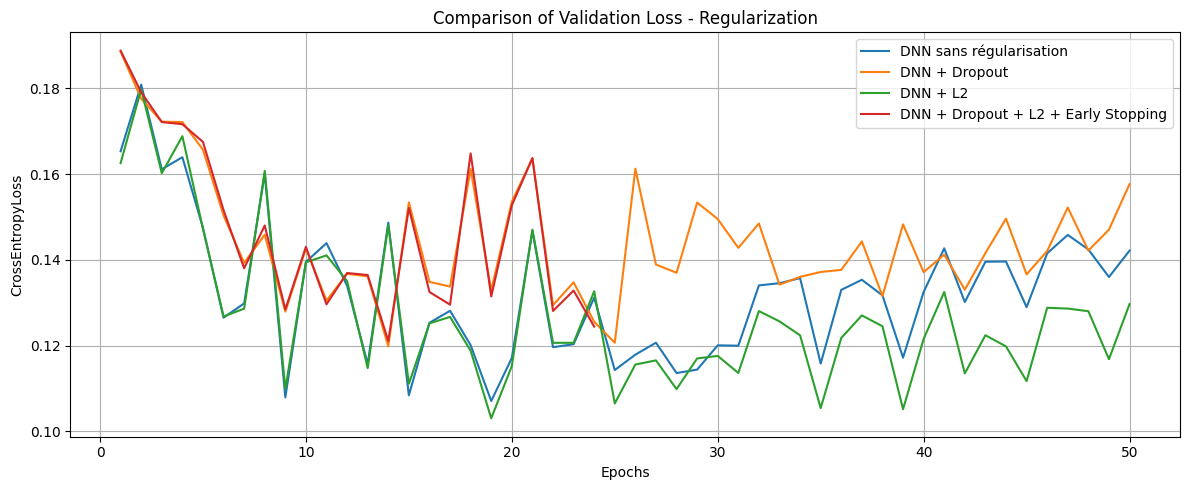

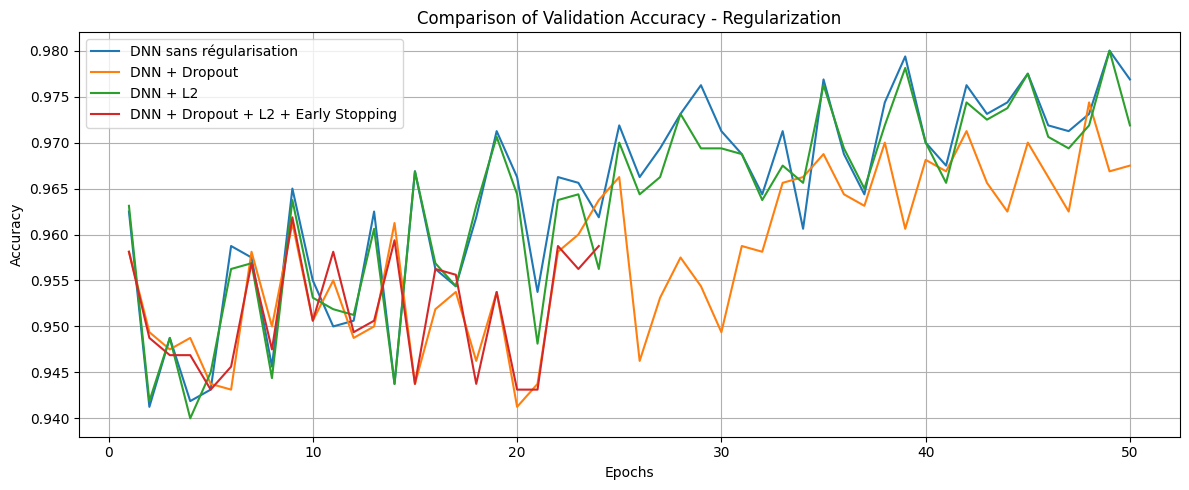

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for name, hist in histories_reg.items():
    plt.plot(
        range(1, len(hist["val_loss"]) + 1),
        hist["val_loss"],
        label=name
    )

plt.title("Comparison of Validation Loss - Regularization")
plt.xlabel("Epochs")
plt.ylabel("CrossEntropyLoss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 5))

for name, hist in histories_reg.items():
    plt.plot(
        range(1, len(hist["val_acc"]) + 1),
        hist["val_acc"],
        label=name
    )

plt.title("Comparison of Validation Accuracy - Regularization")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

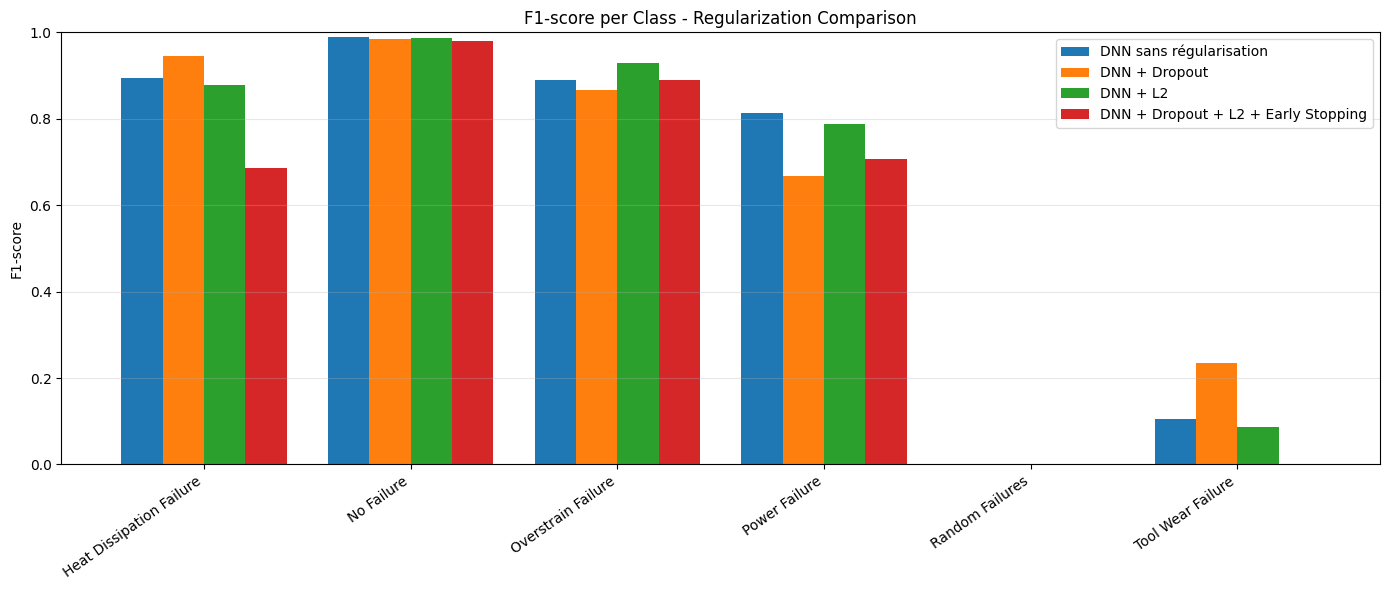

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

class_names = label_encoder.classes_

plt.figure(figsize=(14, 6))

positions = np.arange(len(class_names))
width = 0.2

for i, (name, predictions) in enumerate(predictions_reg.items()):

    scores = f1_score(
        y_val,
        predictions,
        labels=range(6),
        average=None,
        zero_division=0
    )

    plt.bar(
        positions + (i - 1.5) * width,
        scores,
        width,
        label=name
    )

plt.xticks(positions, class_names, rotation=35, ha="right")
plt.ylabel("F1-score")
plt.title("F1-score per Class - Regularization Comparison")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
import numpy as np
import torch

from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTENC
from collections import Counter
from torch.utils.data import TensorDataset, DataLoader

# Standardisation sur le train uniquement
final_scaler = StandardScaler()

X_train_final_scaled = final_scaler.fit_transform(X_train)
X_test_final_scaled = final_scaler.transform(X_test)

# Indices des colonnes catégorielles
categorical_indices = [
    i for i, col in enumerate(X_train.columns)
    if col.startswith("Type_")
]

print("Colonnes catégorielles :", categorical_indices)

# Augmentation uniquement sur le train
counts = Counter(y_train)

strategy = {
    cls: 500
    for cls, count in counts.items()
    if cls != 1 and count < 500
}

final_smote = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=strategy,
    random_state=42,
    k_neighbors=5
)

X_train_final_balanced, y_train_final_balanced = (
    final_smote.fit_resample(
        X_train_final_scaled,
        y_train
    )
)

# Conversion en tenseurs
X_train_final_tensor = torch.tensor(
    np.asarray(X_train_final_balanced),
    dtype=torch.float32
)

y_train_final_tensor = torch.tensor(
    np.asarray(y_train_final_balanced),
    dtype=torch.long
)

X_test_final_tensor = torch.tensor(
    np.asarray(X_test_final_scaled),
    dtype=torch.float32
)

y_test_final_tensor = torch.tensor(
    np.asarray(y_test),
    dtype=torch.long
)

final_loader = DataLoader(
    TensorDataset(
        X_train_final_tensor,
        y_train_final_tensor
    ),
    batch_size=32,
    shuffle=True
)

print("Train final :", X_train_final_tensor.shape)
print("Test final :", X_test_final_tensor.shape)
print("Répartition après SMOTENC :", Counter(y_train_final_balanced))

Colonnes catégorielles : [5, 6, 7]
Train final : torch.Size([10222, 8])
Test final : torch.Size([2000, 8])
Répartition après SMOTENC : Counter({np.int64(1): 7722, np.int64(5): 500, np.int64(4): 500, np.int64(3): 500, np.int64(0): 500, np.int64(2): 500})


In [38]:
import torch.nn as nn

torch.manual_seed(42)

final_model = RegularizedDNN(
    input_size=8,
    hidden_layers=(128, 64),
    num_classes=6,
    dropout_rate=0.2
)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=0.001
)

final_epochs = 50
final_train_losses = []

for epoch in range(final_epochs):

    final_model.train()

    for X_batch, y_batch in final_loader:

        optimizer.zero_grad()

        outputs = final_model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

    final_model.eval()

    with torch.no_grad():
        outputs = final_model(X_train_final_tensor)
        train_loss = criterion(
            outputs,
            y_train_final_tensor
        ).item()

    final_train_losses.append(train_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}/{final_epochs} | "
            f"Train Loss: {train_loss:.4f}"
        )

print("\nEntraînement final terminé !")

Epoch 10/50 | Train Loss: 0.1702
Epoch 20/50 | Train Loss: 0.1105
Epoch 30/50 | Train Loss: 0.0878
Epoch 40/50 | Train Loss: 0.0812
Epoch 50/50 | Train Loss: 0.0662

Entraînement final terminé !


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

final_model.eval()

with torch.no_grad():
    test_outputs = final_model(X_test_final_tensor)
    y_test_pred = test_outputs.argmax(dim=1).numpy()

print("=== DNN + DROPOUT : TEST FINAL ===")

print(f"Accuracy        : {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision Macro : {precision_score(y_test, y_test_pred, average='macro', zero_division=0):.4f}")
print(f"Recall Macro    : {recall_score(y_test, y_test_pred, average='macro', zero_division=0):.4f}")
print(f"F1-score Macro  : {f1_score(y_test, y_test_pred, average='macro', zero_division=0):.4f}")

print("\nClassification Report :")

print(
    classification_report(
        y_test,
        y_test_pred,
        labels=range(6),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

=== DNN + DROPOUT : TEST FINAL ===
Accuracy        : 0.9620
Precision Macro : 0.5291
Recall Macro    : 0.5702
F1-score Macro  : 0.5470

Classification Report :
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.69      0.91      0.78        22
              No Failure       0.99      0.97      0.98      1930
      Overstrain Failure       0.71      0.75      0.73        16
           Power Failure       0.79      0.79      0.79        19
         Random Failures       0.00      0.00      0.00         4
       Tool Wear Failure       0.00      0.00      0.00         9

                accuracy                           0.96      2000
               macro avg       0.53      0.57      0.55      2000
            weighted avg       0.98      0.96      0.97      2000



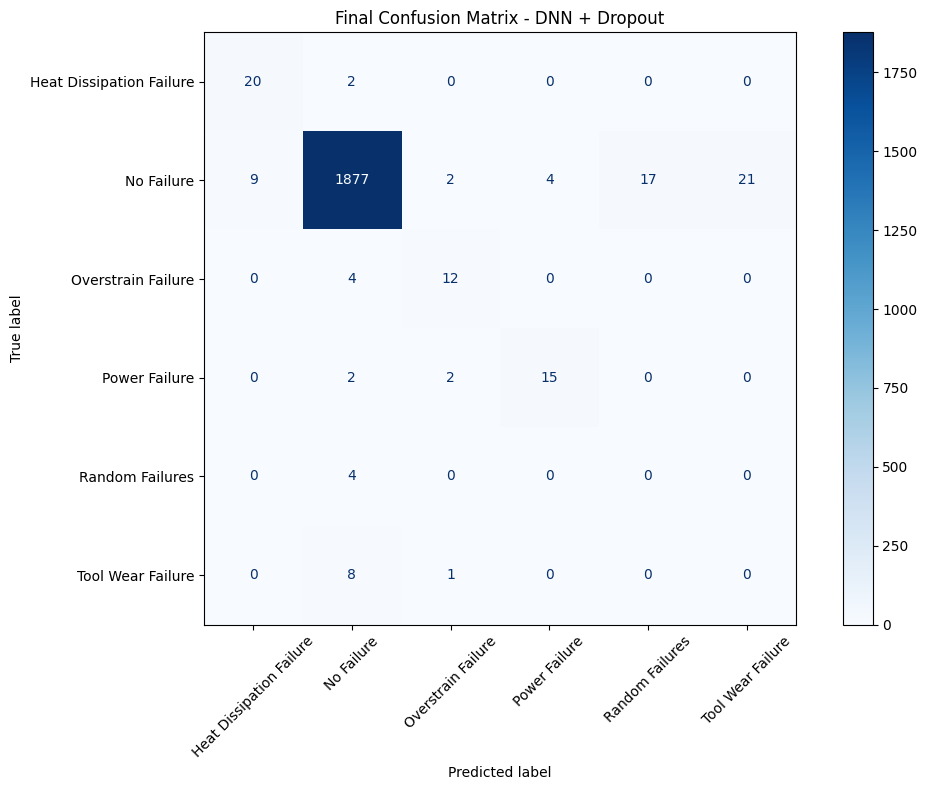

In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_final = confusion_matrix(
    y_test,
    y_test_pred,
    labels=range(6)
)

fig, ax = plt.subplots(figsize=(11, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=label_encoder.classes_
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("Final Confusion Matrix - DNN + Dropout")
plt.tight_layout()
plt.show()

In [41]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# La classe 1 correspond à No Failure
y_baseline = np.full_like(y_test, 1)

comparison_final = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1-score Macro"
    ],
    "Majority Baseline": [
        accuracy_score(y_test, y_baseline),
        precision_score(y_test, y_baseline, average="macro", zero_division=0),
        recall_score(y_test, y_baseline, average="macro", zero_division=0),
        f1_score(y_test, y_baseline, average="macro", zero_division=0)
    ],
    "DNN + Dropout": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred, average="macro", zero_division=0),
        recall_score(y_test, y_test_pred, average="macro", zero_division=0),
        f1_score(y_test, y_test_pred, average="macro", zero_division=0)
    ]
})

display(comparison_final.round(4))

,Metric,Majority Baseline,DNN + Dropout
0,Accuracy,0.9650,0.9620
1,Precision Macro,0.1608,0.5291
2,Recall Macro,0.1667,0.5702
3,F1-score Macro,0.1637,0.5470
